In [ ]:
from scipy.sparse import load_npz
import numpy as np
import pandas as pd
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import load_npz

TOP_K = 10
N_USERS = 150
LIKE_WEIGHT = 1.0        #
DISLIKE_WEIGHT = 0.3     
SEED = 42

In [ ]:
X = load_npz('data/X_tfidf.npz')
recipes = pd.read_csv('data/recipes.csv',usecols=['RecipeId','Name'])
reviews = pd.read_csv('data/reviews.csv',usecols=["RecipeId", "AuthorId", "Rating", "DateSubmitted"])

recipes["RecipeId"] = recipes["RecipeId"].astype(np.int64)

print(f"Liczba przepisów: {len(recipes):,}")
print(f"Liczba recenzji: {len(reviews):,}")
print(f"Macierz TF-IDF: {X.shape}, liczba niezerowych wartości: {X.nnz:,}")

Liczba przepisów: 522,517
Liczba recenzji: 1,401,982
Macierz TF-IDF: (522517, 15000), liczba niezerowych wartości: 20,423,323


In [15]:
id_to_row = pd.Series(
    np.arange(len(recipes), dtype=np.int32),
    index=recipes["RecipeId"]
)

r = reviews[["AuthorId", "RecipeId", "Rating"]].copy()
r["Rating"] = pd.to_numeric(r["Rating"], errors="coerce")
r["RecipeId"] = pd.to_numeric(r["RecipeId"], errors="coerce")
r = r.dropna(subset=["AuthorId", "RecipeId", "Rating"])
r = r[r["Rating"].isin([1, 2, 4, 5])].copy()
r["RecipeId"] = r["RecipeId"].astype(np.int64)
r["row_id"] = r["RecipeId"].map(id_to_row)
r = r.dropna(subset=["row_id"]).copy()
r["row_id"] = r["row_id"].astype(np.int32)
r["liked"] = r["Rating"] >= 4
r = r.drop_duplicates(subset=["AuthorId", "row_id"], keep="last")

counts = r.groupby("AuthorId").agg(
    total=("row_id", "size"),
    likes=("liked", "sum")
)
eligible = counts.index[(counts["total"] >= 3) & (counts["likes"] >= 1)].to_numpy()
if len(eligible) == 0:
    raise ValueError("Brak użytkowników z wystarczającą liczbą ocen.")

selected = np.random.default_rng(SEED).choice(
    eligible, size=min(N_USERS, len(eligible)), replace=False
)
histories = {
    user: group[["row_id", "liked"]].to_numpy()
    for user, group in r[r["AuthorId"].isin(selected)].groupby("AuthorId", sort=False)
}

# Popularność wyliczamy na podstawie liczby pozytywnych ocen przepisu.
popularity = np.bincount(
    r.loc[r["liked"], "row_id"].to_numpy(dtype=np.int64),
    minlength=X.shape[0]
).astype(np.int32)
popular_order = np.argsort(-popularity, kind="stable")

print(f"Liczba profili testowych: {len(histories)}")
print(f"Przepisy z co najmniej jedną pozytywną oceną: {np.count_nonzero(popularity):,}")

Liczba profili testowych: 150
Przepisy z co najmniej jedną pozytywną oceną: 255,322


In [16]:
def make_profile(history):
    ids = history[:, 0].astype(np.int64)
    liked = history[:, 1].astype(bool)
    weights = np.where(liked, LIKE_WEIGHT, -DISLIKE_WEIGHT).astype(np.float32)

    profile = np.asarray(X[ids].T @ weights).ravel().astype(np.float32, copy=False)
    norm = np.linalg.norm(profile)
    if not np.isfinite(norm) or norm == 0:
        return None
    return profile / norm


def select_top_k(scores, seen, k=TOP_K):
    # Wspólne wybieranie Top-K z pominięciem wcześniej ocenionych przepisów.
    scores = scores.copy()
    seen = np.asarray(seen, dtype=np.int64)
    scores[seen] = -np.inf
    k = min(k, len(scores) - len(np.unique(seen)))
    if k <= 0:
        return np.empty(0, dtype=np.int64)

    cutoff = len(scores) - k
    candidates = np.argpartition(scores, cutoff)[cutoff:]
    return candidates[np.lexsort((candidates, -scores[candidates]))]


def cosine_recommend(profile, seen, k=TOP_K):
    scores = np.asarray(X @ profile).ravel()
    return select_top_k(scores, seen, k)


def popular_recommend(seen, k=TOP_K):
    banned = set(np.asarray(seen, dtype=np.int64).tolist())
    recommended = []
    for idx in popular_order:
        if int(idx) not in banned:
            recommended.append(int(idx))
            if len(recommended) == k:
                break
    return np.asarray(recommended, dtype=np.int64)


# Osobna macierz binarna: wartości TF-IDF zastępujemy informacją o obecności cechy.
X_binary = X.copy()
X_binary.eliminate_zeros()
X_binary.data.fill(1.0)
feature_counts = np.diff(X_binary.indptr).astype(np.float32)


def jaccard_recommend(profile, seen, k=TOP_K):
    # W zbiorze cech profilu uwzględniamy tylko dodatnie współrzędne.
    active_features = np.flatnonzero(profile > 0)
    if len(active_features) == 0:
        return np.empty(0, dtype=np.int64)

    binary_profile = np.zeros(X.shape[1], dtype=np.float32)
    binary_profile[active_features] = 1.0

    intersection = np.asarray(X_binary @ binary_profile).ravel()
    union = feature_counts + len(active_features) - intersection
    scores = np.divide(
        intersection, union,
        out=np.zeros_like(intersection),
        where=union > 0
    )
    return select_top_k(scores, seen, k)

In [17]:
N = X.shape[0]
total_positive = int(popularity.sum())
novelty_by_recipe = -np.log2(
    (popularity.astype(np.float64) + 1) / (total_positive + N)
)


def intra_list_diversity(indices):
    if len(indices) < 2:
        return np.nan
    sub = X[indices]
    similarities = (sub @ sub.T).toarray()
    return float(1 - similarities[np.triu_indices(len(indices), k=1)].mean())


def mean_cosine(profile, indices):
    return float(np.asarray(X[indices] @ profile).mean())


methods = ("TF-IDF + Cosine", "Most Popular", "Binary Jaccard")
observations = []
all_suggestions = {name: set() for name in methods}
examples = {}

for user, history in histories.items():
    profile = make_profile(history)
    if profile is None:
        continue
    seen = history[:, 0].astype(np.int64)

    for name in methods:
        start = perf_counter()
        if name == "TF-IDF + Cosine":
            ids = cosine_recommend(profile, seen)
        elif name == "Most Popular":
            ids = popular_recommend(seen)
        else:
            ids = jaccard_recommend(profile, seen)
        duration_ms = (perf_counter() - start) * 1000

        if len(ids) == 0:
            continue

        all_suggestions[name].update(ids.tolist())
        observations.append({
            "user": user,
            "method": name,
            "diversity": intra_list_diversity(ids),
            "novelty": float(novelty_by_recipe[ids].mean()),
            "mean_cosine": mean_cosine(profile, ids),
            "latency_ms": duration_ms,
        })
        examples.setdefault(name, ids.copy())

obs = pd.DataFrame(observations)
results = obs.groupby("method").agg(
    users=("user", "nunique"),
    intra_list_diversity=("diversity", "mean"),
    novelty=("novelty", "mean"),
    mean_cosine_diagnostic=("mean_cosine", "mean"),
    latency_p50_ms=("latency_ms", "median"),
    latency_p95_ms=("latency_ms", lambda series: series.quantile(0.95)),
)
results["unique_recommended"] = pd.Series({
    name: len(ids) for name, ids in all_suggestions.items()
})
results["catalog_coverage_pct"] = results["unique_recommended"] / N * 100

display(results.round(4))

,users,intra_list_diversity,novelty,mean_cosine_diagnostic,latency_p50_ms,latency_p95_ms,unique_recommended,catalog_coverage_pct
method,,,,,,,,
Binary Jaccard,150,0.7550,19.2025,0.3012,16.2288,25.8092,1101,0.2107
Most Popular,150,0.9365,10.3585,0.1136,0.0103,0.0265,13,0.0025
TF-IDF + Cosine,150,0.6196,19.2689,0.3936,14.5049,23.8120,1376,0.2633


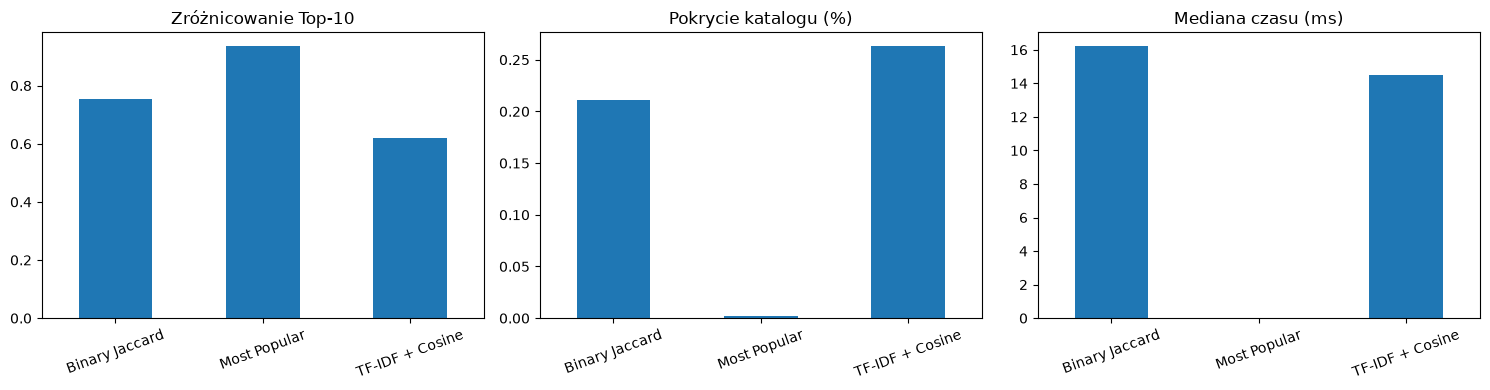


TF-IDF + Cosine


,RecipeId,Name
0,17258,Easy Chicken Casserole
1,82561,Tortilla Crunch Chicken Fingers
2,139060,Your Basic Quesadilla
3,177405,Chicken Fingers
4,180219,Cherry Jam Chicken
5,263305,Cereal-Breaded Baked Chicken Tenders
6,14152,Beef Stroganoff Sandwich
7,28214,Pizza Biscuit Bake
8,178318,Oven-Fried Chicken
9,187269,Grilled Cheese for Garlic Lovers!



Most Popular


,RecipeId,Name
0,45809,Bourbon Chicken
1,2886,Best Banana Bread
2,39087,Creamy Cajun Chicken Pasta
3,89204,Crock-Pot Chicken With Black Beans &amp; Cream...
4,35813,Oatmeal Raisin Cookies
5,67256,Best Ever Banana Cake With Cream Cheese Frosting
6,22782,Jo Mama's World Famous Spaghetti
7,54257,"Yes, Virginia There is a Great Meatloaf"
8,32204,&quot;Whatever Floats Your Boat&quot; Brownies!
9,69173,Kittencal's Italian Melt-In-Your-Mouth Meatballs



Binary Jaccard


,RecipeId,Name
0,191087,Easy Sesame Chicken With Apricot Sauce
1,290699,Incredible Peking Chicken!
2,108841,Shanghai Fried Noodles With Pork or Chicken
3,245771,Easy Chipotle BBQ Chicken Wraps
4,196606,Easy Cheesy Chicken Macaroni-Tomato Skillet
5,463580,Skillet Fajitas Supremas
6,204169,Summer Pasta Primavera
7,110115,Healthier Style Chicken Nuggets
8,258065,Leftover Shredded Beef (Or Chicken or Shrimp) ...
9,403121,Dynasty Chow Funn Noodles


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column, title in zip(
    axes,
    ["intra_list_diversity", "catalog_coverage_pct", "latency_p50_ms"],
    ["Zróżnicowanie Top-10", "Pokrycie katalogu (%)", "Mediana czasu (ms)"]
):
    results[column].plot(kind="bar", ax=ax, rot=0)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelrotation=20)
plt.tight_layout()
plt.show()

# Przykładowe rekomendacje z nazwami przepisów.
for name, ids in examples.items():
    print(f"\n{name}")
    display(recipes.iloc[ids][["RecipeId", "Name"]].reset_index(drop=True))